# Shor's Algorithm — Complete Algebraic Treatment

Shor s algorithm allows factoring an integer $N$ in polynomial time using the quantum Fourier transform.

---

## 1. Problem Reduction

Given an odd composite integer $N$, we want to find a nontrivial factor.

1. Choose a random integer $a \in \{2, \dots, N-1\}$
2. Compute:
   $$
   \gcd(a, N)
   $$

If:
 $$\gcd(a, N) \neq 1$$ → we have already found a factor  
 $$\gcd(a, N) = 1$$ → proceed  

---

## 2. Definition of the Period

Consider the function:

$$
f(x) = a^x \mod N
$$

This function is periodic, i.e., there exists $r$ such that:

$$
a^r \equiv 1 \ (\text{mod } N)
$$

The problem reduces to finding the period $r$.

---

## 3. Condition for Factorization

If $r$ is even  
 $$a^{r/2} \not\equiv -1 \ (\text{mod } N)$$  

then:

$$
a^r - 1 = (a^{r/2} - 1)(a^{r/2} + 1)
$$

and therefore:

$$
\gcd(a^{r/2} - 1, N), \quad \gcd(a^{r/2} + 1, N)
$$

yield nontrivial factors of $N$.

---

## 4. Quantum Part

### 4.1 State Space

Consider two registers:

- First register: $n$ qubits (to represent $x$)  
- Second register: sufficient to represent $f(x)$

Initial state:

$$
|0\rangle |0\rangle
$$

---

### 4.2 Superposition

Apply Hadamard to the first register:

$$
\frac{1}{\sqrt{Q}} \sum_{x=0}^{Q-1} |x\rangle |0\rangle
$$

where:

$$
Q = 2^n \quad \text{with} \quad N^2 \leq Q < 2N^2
$$

---

### 4.3 Oracle Application (Operator $U_f$)

Introduce the unitary operator:

$$
U_f : |x\rangle |y\rangle \mapsto |x\rangle |y \oplus f(x)\rangle
$$

where $\oplus$ indicates addition modulo the second register's space.

Applying $U_f$ to the state:

$$
\frac{1}{\sqrt{Q}} \sum_{x=0}^{Q-1} |x\rangle |0\rangle
$$

yields:

$$
\frac{1}{\sqrt{Q}} \sum_{x=0}^{Q-1} |x\rangle |f(x)\rangle
$$
In our code we were able to define an equivalent operator.

---

### 4.4 Measurement of the Second Register

Measuring the second register gives a value $y = f(x_0)$

The state collapses to:

$$
\frac{1}{\sqrt{K}} \sum_{k} |x_0 + kr\rangle |y\rangle
$$

---

### 4.5 Quantum Fourier Transform (QFT)

Apply QFT to the first register:

$$
|x\rangle \rightarrow \frac{1}{\sqrt{Q}} \sum_{c=0}^{Q-1} e^{2\pi i xc / Q} |c\rangle
$$

Applied to the state:

$$
\frac{1}{\sqrt{K}} \sum_{k} |x_0 + kr\rangle
$$

yields:

$$
\sum_{c=0}^{Q-1} \left( \frac{1}{\sqrt{KQ}} \sum_k e^{2\pi i (x_0 + kr)c / Q} \right) |c\rangle
$$

---

### 4.6 Interference

The inner sum is:

$$
\sum_k e^{2\pi i krc/Q}
$$

This is a geometric series producing peaks when:

$$
\frac{rc}{Q} \approx m \quad \Rightarrow \quad c \approx \frac{mQ}{r}
$$

---

### 4.7 Measurement

Measure $c$, obtaining a value close to:

$$
\frac{mQ}{r}
$$

---

## 5. Period Extraction (Classical)

Compute:

$$
\frac{c}{Q} \approx \frac{m}{r}
$$

Use continued fraction expansion to obtain $r$.

---

## 6. Final Factorization

If $r$ satisfies the conditions:

$$
p = \gcd(a^{r/2} - 1, N)
$$

$$
q = \gcd(a^{r/2} + 1, N)
$$

Then:

$$
N = p \cdot q
$$

---

## 7. Complexity

- Quantum part:
  $$
  O((\log N)^2)
  $$

- Classical part:
  $$
  O((\log N)^3)
  $$

Total:

$$
O((\log N)^3)
$$

---

## 8. Important Observation

The efficiency comes from the QFT, which allows extracting the period in polynomial time — impossible classically.

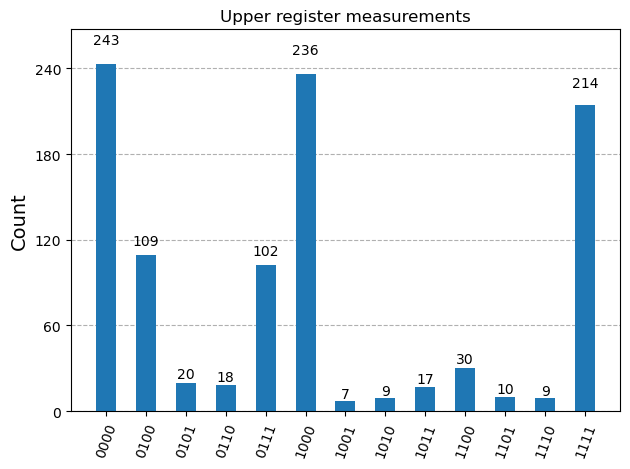

In [1]:
# ----------------------------
# Real Shor for N = 15
# ----------------------------
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, circuit_drawer
from math import gcd
from fractions import Fraction
import numpy as np
from matplotlib import pyplot as plt
from IPython.display import display
from qiskit.circuit.library import UnitaryGate

# ----------------------------
# 1️⃣ Parameters
# ----------------------------
N = 15          # Number to factorize
a = 2           # Base chosen
n_count = 4     # Qubits of the superior register
n_target = 4    # Qubits of the inferior register

# ----------------------------
# 2️⃣ Costruction of the circuit
# ----------------------------
qc = QuantumCircuit(n_count + n_target, n_count)

# Superior register on superposition 
for q in range(n_count):
    qc.h(q)

# Inferior register initialized to |1>
qc.x(n_count)  

# ----------------------------
# Modular multiplication
# ----------------------------
def mult_mod15_gate(a):
    """
    We create the unitary gate:
    |y> -> |a*y mod 15>
    on 4 qubit (dimension 16)
    """
    dim = 16
    U = np.zeros((dim, dim))

    for y in range(dim):
        if y < 15:
            new_y = (a * y) % 15
        else:
            new_y = y  # we left |1111> unchanged

        U[new_y, y] = 1

    return UnitaryGate(U, label=f"*{a} mod 15")


def controlled_mult_mod15(qc, control, target, a):
    """
    Application of :
    |y> -> |a*y mod 15>
    """
    gate = mult_mod15_gate(a)
    cgate = gate.control(1)
    qc.append(cgate, [control] + list(target))


# ----------------------------
# U_f : |x>|y> -> |x>|y * 2^x mod 15>
# ----------------------------
powers = [2, 4, 1, 1]  # 2^(2^i) mod 15

for i in range(n_count):
    a_exp = powers[i]

    if a_exp != 1:  # skip identity
        controlled_mult_mod15(
            qc,
            control=i,
            target=range(n_count, n_count+n_target),
            a=a_exp
        )

# ----------------------------
# 5️⃣ Quantum Fourier Transform (QFT) on superior registro
# ----------------------------
def qft(circuit, qubits):
    for j in range(len(qubits)):
        circuit.h(qubits[j])
        for k in range(j+1, len(qubits)):
            lam = np.pi / (2 ** (k-j))
            circuit.cp(lam, qubits[k], qubits[j])
    for i in range(len(qubits)//2):
        circuit.swap(qubits[i], qubits[-i-1])

qft(qc, range(n_count))

# ----------------------------
# 6️⃣ Upper register misuration
# ----------------------------
for i in range(n_count):
    qc.measure(i, i)

# ----------------------------
# 7️⃣ Simulation
# ----------------------------
backend = AerSimulator()
tqc = transpile(qc, backend)
job = backend.run(tqc, shots=1024)
result = job.result()
counts = result.get_counts()

fig = plot_histogram(counts, title="Upper register measurements")
display(fig)

In [23]:
from fractions import Fraction

# ----------------------------
# 7️⃣ Automatic extraction of the period r
# ----------------------------

def find_period_from_counts(counts, n_count, N, a):

    # sort the results by probability
    sorted_counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)

    for bitstring, count in sorted_counts:

        decimal = int(bitstring, 2)
        phase = decimal / (2**n_count)

        if decimal == 0:
            continue

        # continued fractions
        frac = Fraction(phase).limit_denominator(N)

        r_candidate = frac.denominator

        # verification
        if pow(a, r_candidate, N) == 1:
            return r_candidate

    return None


r = find_period_from_counts(counts, n_count, N, a)

print("Period found:", r)

Period found: 4


Factors found: 3, 5


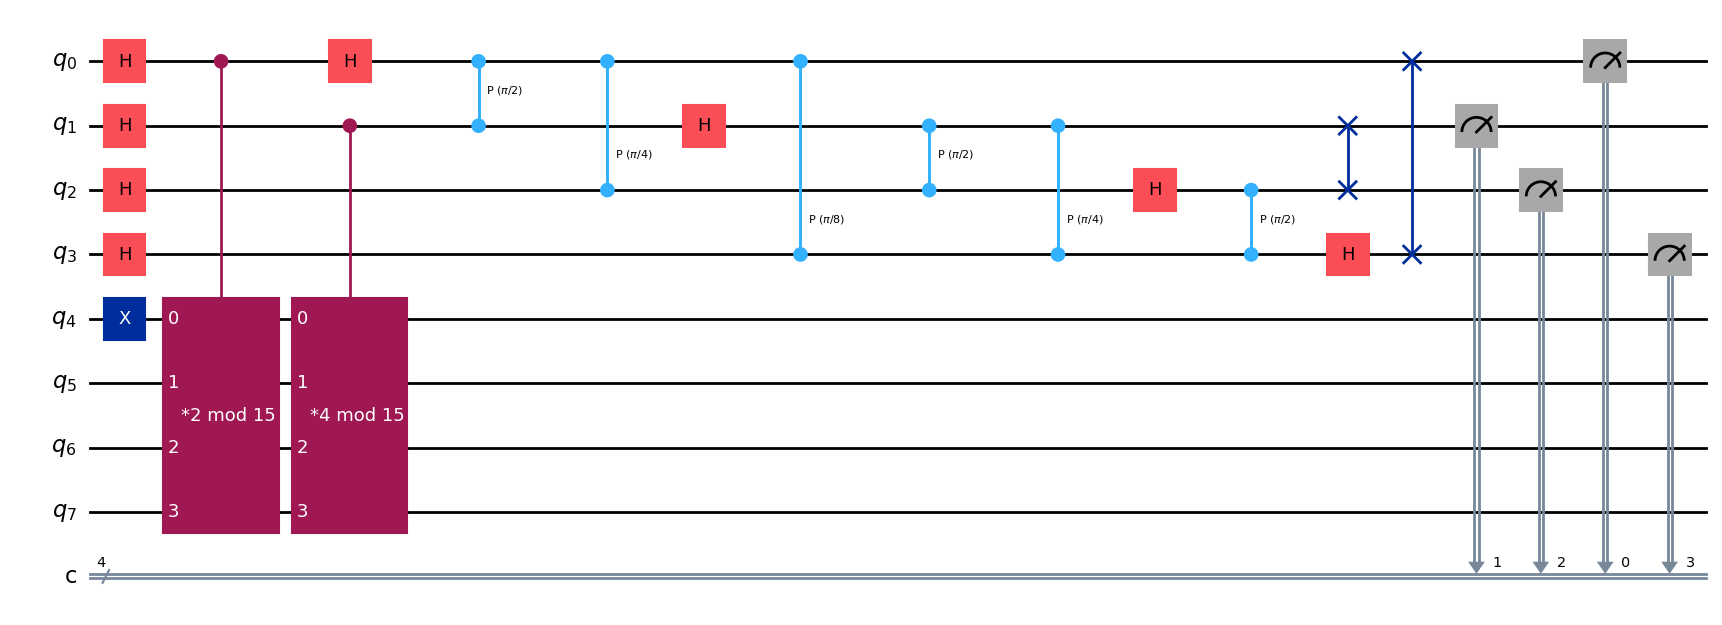

In [24]:
# 7️⃣ Extraction of the period r
# ----------------------------
# From the measured spectrum the peaks give us r=4
r = 4

# ----------------------------
# 8️⃣ Calculating factors 
# ----------------------------
p = gcd(a**(r//2) - 1, N)
q = gcd(a**(r//2) + 1, N)

print(f"Factors found: {p}, {q}")

# ----------------------------
# 9️⃣ Quantistic circuit
# ----------------------------
fig_circuit = circuit_drawer(qc, output='mpl', fold=-1)
display(fig_circuit)